## Dodgers Pitch Arsenal Classifier - Milestone 3: Visualizations & Story
#### This notebook builds the signature pitch movement plot for each pitcher and tells the story of what makes one pitch stand out.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

## 1. Load Data

#### Load the cleaned pitch data saved by 01_exploration (`data/pitches_clean.csv`). It contains 5,384 pitches from Yamamoto, Glasnow, and Stone, with missing values and sweepers (ST) already removed. Statcast stores names as "Last, First", so the check below confirms the exact spelling used to filter each pitcher.

In [2]:
pitches = pd.read_csv("data/pitches_clean.csv")
print("Rows:", len(pitches))
print()
print(pitches['player_name'].value_counts())
print()
print(pitches.groupby('player_name')['pitch_type'].value_counts())   # each pitcher's arsenal

Rows: 5384

player_name
Stone, Gavin           2116
Glasnow, Tyler         1849
Yamamoto, Yoshinobu    1419
Name: count, dtype: int64

player_name          pitch_type
Glasnow, Tyler       FF            823
                     SL            504
                     CU            355
                     SI            167
Stone, Gavin         CH            574
                     FF            557
                     SI            465
                     SL            318
                     FC            111
                     CU             91
Yamamoto, Yoshinobu  FF            579
                     FS            345
                     CU            329
                     FC             78
                     SL             47
                     SI             41
Name: count, dtype: int64


## 2. Pitch Movement Plots

#### The signature plot of pitch analytics shows horizontal movement (`pfx_x`) against vertical movement (`pfx_z`), with one dot per pitch, colored by pitch type. Movement is converted from feet to inches, and the view is from behind the catcher.

#### All three pitchers are right-handed, so **left = arm side** (where sinkers and changeups run) and **right = glove side** (where sliders and cutters break). The vertical axis shows **induced vertical break**, which is movement caused by spin with gravity taken out. Every pitch falls on its way to the plate. Points above zero drop **less** than a ball thrown with no spin (backspin holds them up), and points below zero drop **more** (topspin pulls them down). Every plot uses the same axes and the same color for each pitch, so the three arsenals can be compared directly.

In [3]:
pitch_names = {
    'FF': 'Four-Seam Fastball',
    'SI': 'Sinker',
    'FC': 'Cutter',
    'SL': 'Slider',
    'CU': 'Curveball',
    'CH': 'Changeup',
    'FS': 'Splitter'
}

# One fixed color per pitch, so every pitcher's chart uses the same colors
pitch_colors = {
    'FF': '#d62728',
    'SI': '#ff7f0e',
    'FC': '#8c564b',
    'SL': '#2ca02c',
    'CU': '#1f77b4',
    'CH': '#9467bd',
    'FS': '#e377c2'
}

def plot_movement(df, player_name, title, save_path=None):
    pitcher_df = df[df['player_name'] == player_name]

    fig, ax = plt.subplots(figsize=(9, 8))
    for pt, grp in pitcher_df.groupby('pitch_type'):
        ax.scatter(grp['pfx_x'] * 12, grp['pfx_z'] * 12,   # feet -> inches
                   label=f"{pitch_names.get(pt, pt)} ({len(grp)})",
                   color=pitch_colors.get(pt, 'gray'),
                   alpha=0.5, s=30)

    ax.axhline(0, color='gray', linewidth=0.8)
    ax.axvline(0, color='gray', linewidth=0.8)
    ax.set_xlim(-25, 25)   # same axes for every pitcher so plots are comparable
    ax.set_ylim(-25, 25)
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Horizontal Movement (inches)   <- arm side | glove side ->")
    ax.set_ylabel("Induced Vertical Break (inches)   <- more drop | less drop ->")
    ax.legend(title='Pitch Type', loc='best')
    ax.grid(alpha=0.3)

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

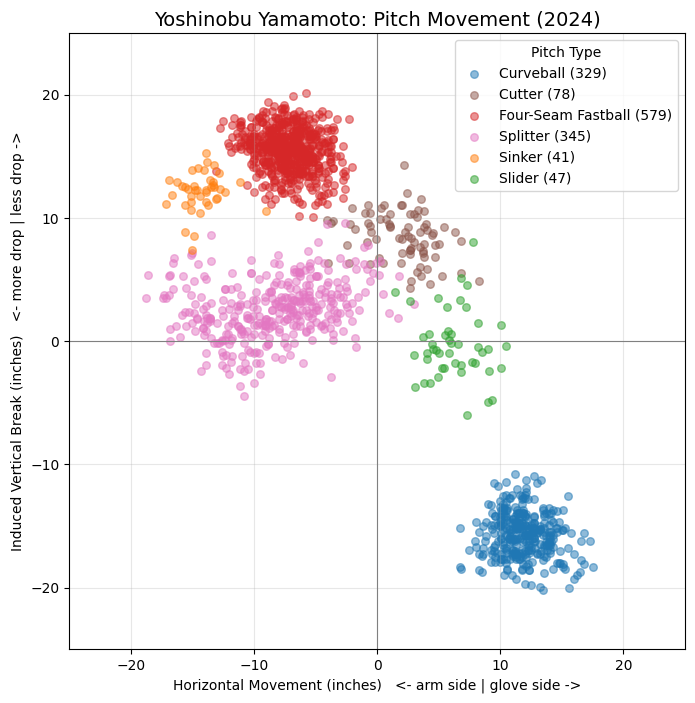

In [4]:
plot_movement(pitches, 'Yamamoto, Yoshinobu', 'Yoshinobu Yamamoto: Pitch Movement (2024)',
              save_path='images/yamamoto_movement.png')

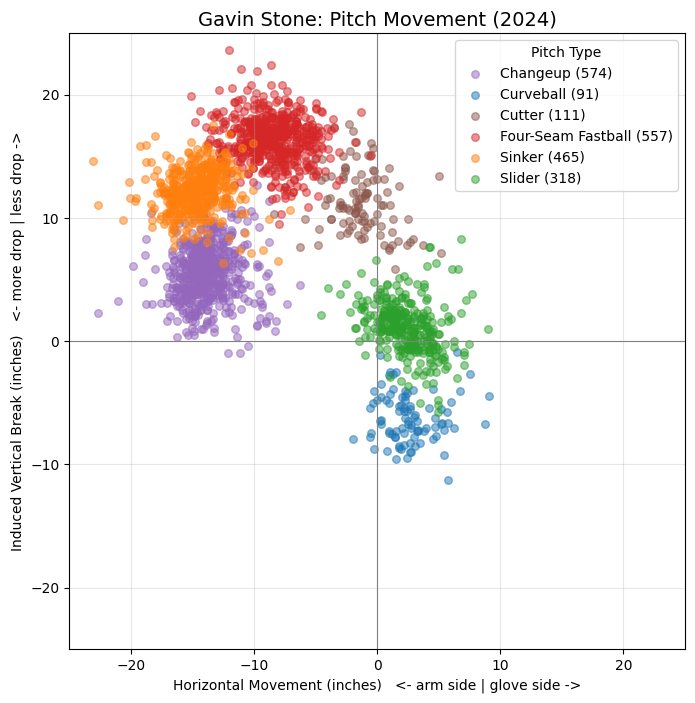

In [5]:
plot_movement(pitches, 'Stone, Gavin', 'Gavin Stone: Pitch Movement (2024)')

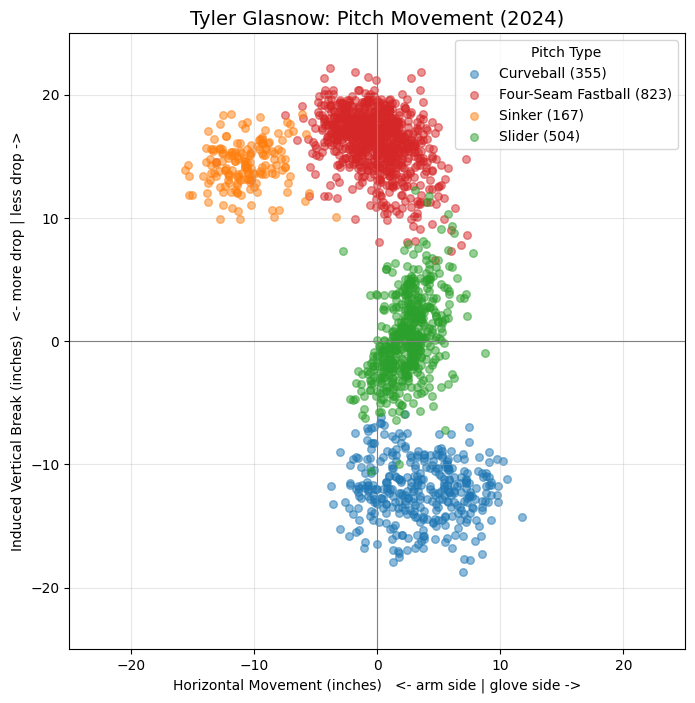

In [6]:
plot_movement(pitches, 'Glasnow, Tyler', 'Tyler Glasnow: Pitch Movement (2024)')

## 3. The Story: Yamamoto's Splitter

#### Yamamoto's movement plot shows two clusters stacked on top of each other on the arm side: the red four-seam fastball and the pink splitter. The table below compares the two pitches directly.

In [7]:
yamamoto = pitches[pitches['player_name'] == 'Yamamoto, Yoshinobu']

compare = (yamamoto[yamamoto['pitch_type'].isin(['FF', 'FS'])]
           .groupby('pitch_type')
           .agg(pitches=('pitch_type', 'size'),
                speed_mph=('release_speed', 'mean'),
                spin_rpm=('release_spin_rate', 'mean'),
                horizontal_in=('pfx_x', lambda s: (s * 12).mean()),
                vertical_break_in=('pfx_z', lambda s: (s * 12).mean()))
           .round(1))
compare.index = compare.index.map(pitch_names)
compare

,pitches,speed_mph,spin_rpm,horizontal_in,vertical_break_in
pitch_type,,,,,
Four-Seam Fastball,579,95.5,2155.8,-7.2,15.5
Splitter,345,90.2,1324.4,-8.4,2.6


#### Out of the hand, Yamamoto's splitter looks like a fastball. It travels the same lane — both pitches move about 7–8 inches to the arm side — and arrives only 5 mph slower. The difference is spin: the splitter generates 1,324 rpm compared with 2,156 rpm on the four-seamer. Without that backspin to hold the ball up, it ends up roughly 13 inches lower than the fastball a hitter thought they were reading. On the movement plot, that's the pink cluster sitting directly below the red one — same horizontal lane, dramatically different drop.

#### The model had no trouble separating them. Not a single splitter was misclassified in 02_modeling. Hitters don't get that luxury.